# Imports

In [1]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

!pip install torchinfo
from torchinfo import summary

import requests

# Tokenizers

In [2]:
# Eleuther's tokenizer
tokenizer = AutoTokenizer.from_pretrained('EleutherAI/gpt-neo-125m')
tokenizer.pad_token_id = tokenizer.encode(' ')[0]

# load in two GPTneo's and push to GPU
model_alice = AutoModelForCausalLM.from_pretrained('EleutherAI/gpt-neo-125m')
model_edgar = AutoModelForCausalLM.from_pretrained('EleutherAI/gpt-neo-125m')

# GPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
model_alice = model_alice.to(device)
model_edgar = model_edgar.to(device)

Loading weights:   0%|          | 0/160 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125m
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/160 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125m
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


# Inspect the Model

In [3]:
# inspect the model
model_alice

GPTNeoForCausalLM(
  (transformer): GPTNeoModel(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(2048, 768)
    (drop): Dropout(p=0.0, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPTNeoBlock(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPTNeoAttention(
          (attention): GPTNeoSelfAttention(
            (attn_dropout): Dropout(p=0.0, inplace=False)
            (resid_dropout): Dropout(p=0.0, inplace=False)
            (k_proj): Linear(in_features=768, out_features=768, bias=False)
            (v_proj): Linear(in_features=768, out_features=768, bias=False)
            (q_proj): Linear(in_features=768, out_features=768, bias=False)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPTNeoMLP(
          (c_fc): Linear(in_features=768, out_features=3072, bias=True)
          (c_proj): Linear(in_fe

In [4]:
# accessing a prticular weights matrix
model_alice.transformer.h[3].attn.attention.k_proj.weight.shape

torch.Size([768, 768])

In [5]:
# model summary
x = tokenizer.encode('What did the Red Queen say to Alice?', return_tensors='pt').to(device)
summary(model_alice, input_data = x, col_names = ['input_size', 'output_size', 'num_params'])

Layer (type:depth-idx)                                  Input Shape               Output Shape              Param #
GPTNeoForCausalLM                                       [1, 9]                    --                        --
├─GPTNeoModel: 1-1                                      [1, 9]                    --                        --
│    └─Embedding: 2-1                                   [1, 9]                    [1, 9, 768]               38,597,376
│    └─Embedding: 2-2                                   [1, 9]                    [1, 9, 768]               1,572,864
│    └─Dropout: 2-3                                     [1, 9, 768]               [1, 9, 768]               --
│    └─ModuleList: 2-4                                  --                        --                        --
│    │    └─GPTNeoBlock: 3-1                            [1, 9, 768]               [1, 9, 768]               7,085,568
│    │    └─GPTNeoBlock: 3-2                            [1, 9, 768]               [1,

In [6]:
# are the embeddings and unembeddings tied?
print('** Embedding:\n', model_alice.transformer.wte.weight.detach())
print('\n** Unembeddings:\n', model_alice.lm_head.weight.detach())

** Embedding:
 tensor([[ 0.1709, -0.7383,  0.4277,  ...,  0.0840,  0.5820, -0.3457],
        [ 0.2070, -0.6055,  0.4590,  ...,  0.1562,  0.4883, -0.2363],
        [ 0.2324, -0.6367,  0.3262,  ...,  0.2236,  0.7500, -0.2354],
        ...,
        [ 0.7734, -1.1406,  0.6523,  ...,  0.2832,  0.9258, -0.5547],
        [ 0.3906, -0.8438,  0.5117,  ...,  0.0148,  0.6992, -0.2383],
        [ 0.2734, -0.7148,  0.2949,  ...,  0.1748,  0.4043, -0.3105]],
       device='cuda:0')

** Unembeddings:
 tensor([[ 0.1709, -0.7383,  0.4277,  ...,  0.0840,  0.5820, -0.3457],
        [ 0.2070, -0.6055,  0.4590,  ...,  0.1562,  0.4883, -0.2363],
        [ 0.2324, -0.6367,  0.3262,  ...,  0.2236,  0.7500, -0.2354],
        ...,
        [ 0.7734, -1.1406,  0.6523,  ...,  0.2832,  0.9258, -0.5547],
        [ 0.3906, -0.8438,  0.5117,  ...,  0.0148,  0.6992, -0.2383],
        [ 0.2734, -0.7148,  0.2949,  ...,  0.1748,  0.4043, -0.3105]],
       device='cuda:0')


# Explore the Tokenizer

In [7]:
# A bit about their tokenizer
print(f'Tokenizer has {tokenizer.vocab_size:,} tokens.\nA few random tokens:\n')

for i in range(30):
  # generate a random token
  rand_tok = torch.randint(tokenizer.vocab_size, (1,))
  print(f'Token {rand_tok[0]:5} is "{tokenizer.decode(rand_tok)}"')

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Tokenizer has 50,257 tokens.
A few random tokens:

Token   580 is " 201"
Token 28557 is " healed"
Token 32026 is " Slot"
Token 36539 is " knocks"
Token  8497 is "hesis"
Token 25551 is " Occupy"
Token 22980 is "265"
Token  3037 is " technology"
Token 26457 is " dictatorship"
Token 40156 is "GUI"
Token 31545 is " intolerance"
Token 12223 is " Crown"
Token    76 is "m"
Token 12232 is " Brooklyn"
Token 42248 is "witch"
Token 42309 is " fluorescent"
Token 39245 is " Paso"
Token  4925 is " freedom"
Token  6294 is " fired"
Token 17617 is "stairs"
Token 41191 is "Miami"
Token 45664 is "mbuds"
Token  9163 is "sylv"
Token 10889 is " Sure"
Token 47013 is " EPS"
Token 36953 is " scarf"
Token 40141 is "Orange"
Token 36440 is " woo"
Token 27168 is " Nim"
Token  7462 is " domin"


In [8]:
# check the raw output shape
into = tokenizer.encode('What did the Red Queen say to Alice?', return_tensors='pt').to(device)

out = model_alice(into)
print(out.logits.shape) # [batch, tokens, embedding]

torch.Size([1, 9, 50257])


In [9]:
# text generation
out = model_alice.generate(into,
                           max_new_tokens=120,
                           do_sample=True,
                           pad_token_id = 50256)
print(tokenizer.decode(out[0].cpu()))

What did the Red Queen say to Alice?

The French were the best.

Alice would never say "No" or "Yes! No! Yes!"

Alice, and her mother, would never say "No! No!"

Alice knew how to talk.
TWENTY-SIX, BOREN'S DREAM

Alice knew how to open the door.

There was the room a little older than she would have liked. The bedroom was simple, warm, and clean, but the bed on the right of the chandelle was large and light. The ceiling was covered with


In [10]:
# is it different from GPT's tokenizer?
from transformers import GPT2Tokenizer
gpt_tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
gpt_tokenizer

GPT2Tokenizer(name_or_path='gpt2', vocab_size=50257, model_max_length=1024, padding_side='right', truncation_side='right', special_tokens={'bos_token': '<|endoftext|>', 'eos_token': '<|endoftext|>', 'unk_token': '<|endoftext|>'}, added_tokens_decoder={
	50256: AddedToken("<|endoftext|>", rstrip=False, lstrip=False, single_word=False, normalized=True, special=True),
})

In [11]:
for i in range(30):
  # generate a random token
  randtok = torch.randint(tokenizer.vocab_size,(1,))

  # get the token text for both tokenizers
  e = tokenizer.decode(randtok) # gpt-neo
  g = gpt_tokenizer.decode(randtok) # gpt2
  print(f'Token {randtok[0]:5} is "{e}" and "{g}"')

Token 45675 is "Excellent" and "Excellent"
Token 36843 is " adventurers" and " adventurers"
Token 48443 is "!/" and "!/"
Token 43198 is "Decre" and "Decre"
Token 14427 is " toug" and " toug"
Token  8851 is " ren" and " ren"
Token 26696 is "oppy" and "oppy"
Token 31189 is " Tribunal" and " Tribunal"
Token 46479 is "�" and "�"
Token 20733 is " Sonia" and " Sonia"
Token 26652 is "topic" and "topic"
Token 21482 is "wage" and "wage"
Token 23623 is " rebound" and " rebound"
Token 31766 is " SJ" and " SJ"
Token 30241 is " autopsy" and " autopsy"
Token 29794 is "uko" and "uko"
Token 19591 is "Ray" and "Ray"
Token  4594 is "aste" and "aste"
Token 43431 is " inund" and " inund"
Token 20909 is "ointed" and "ointed"
Token  3916 is "igned" and "igned"
Token 35035 is " oppress" and " oppress"
Token 48327 is " assassinate" and " assassinate"
Token 49830 is " unorthodox" and " unorthodox"
Token 47890 is " Razer" and " Razer"
Token 27920 is ")—" and ")—"
Token  8254 is "iger" and "iger"
Token 20362 is 

# Import and Process Texts

In [12]:
# Through the Looking Glass (aka Alice in Wornderland)
text = requests.get('https://www.gutenberg.org/cache/epub/11/pg11.txt').text
alice_tokens = torch.tensor(tokenizer.encode(text), dtype=torch.long)

# Edgar Allen Poe
text = requests.get('https://www.gutenberg.org/cache/epub/2148/pg2148.txt').text
edgar_tokens = torch.tensor(tokenizer.encode(text), dtype=torch.long)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (52948 > 2048). Running this sequence through the model will result in indexing errors


In [13]:
# summary
print(f'Alice in Wonderland has  {len(alice_tokens):7,} tokens.')
print(f'Edgar Allen Poe text has {len(edgar_tokens):7,} tokens.')

Alice in Wonderland has   52,948 tokens.
Edgar Allen Poe text has 197,302 tokens.


# Prepare for fine-tuning

In [14]:
# ALICE optimizer
optimizer_alice = torch.optim.AdamW(model_alice.parameters(), lr=5e-5, weight_decay=.01)

# EDGAR optimizer
optimizer_edgar = torch.optim.AdamW(model_edgar.parameters(), lr=5e-5, weight_decay=.01)

In [15]:
# training parameters
seq_len     = 256 # max sequence length
batch_size  = 16
num_samples = 476

# Fine-tune the model

In [16]:
token_probs = np.zeros((num_samples, 3))

# initialize losses
loss_alice = np.zeros(num_samples)
loss_edgar = np.zeros(num_samples)

# loop over training
for sampl_i in range(num_samples):

  ### --- ALICE fine-tuning ---
  # get a batch of data
  ix = torch.randint(len(alice_tokens)-seq_len, size = (batch_size,))
  X  = alice_tokens[ix[:,None] + torch.arange(seq_len)].to(device)

  # forward pass and get loss
  model_alice.zero_grad() # we can also use optimizer.zero_grad() which is more traditional approach
  outputs = model_alice(X, labels = X) # fine crossentropy loss (t, t+1) HuggingFace interface

  # backprop and store loss
  outputs.loss.backward() # we don't have specified loss since its defined in model_alice so we need to refer to it manually
  optimizer_alice.step()
  loss_alice[sampl_i] = outputs.loss.item()
  ### -------------------------

  ### --- EDGAR fine-tuning ---
  # get the batch of data
  ix = torch.randint(len(edgar_tokens)-seq_len, size = (batch_size,))
  X  = edgar_tokens[ix[:,None] + torch.arange(seq_len)].to(device)

  # forward pass and get loss
  model_edgar.zero_grad()
  outputs = model_edgar(X, labels = X)

  # backprop and store loss
  outputs.loss.backward()
  optimizer_edgar.step()
  loss_edgar[sampl_i] = outputs.loss.item()
  ### --------------------------

  # update progress display
  if sampl_i % 77 == 0:
    print(f'Sample {sampl_i:4}/{num_samples}, losses (Alice/Edgar): {loss_alice[sampl_i]:.4f} / {loss_edgar[sampl_i]:.4f}')

Sample    0/476, losses (Alice/Edgar): 2.6185 / 2.7773
Sample   77/476, losses (Alice/Edgar): 1.6082 / 2.2866
Sample  154/476, losses (Alice/Edgar): 1.2648 / 2.1441
Sample  231/476, losses (Alice/Edgar): 0.7828 / 1.7565
Sample  308/476, losses (Alice/Edgar): 0.3834 / 1.7387
Sample  385/476, losses (Alice/Edgar): 0.2962 / 1.7287
Sample  462/476, losses (Alice/Edgar): 0.1938 / 1.4674


# Plot Losses

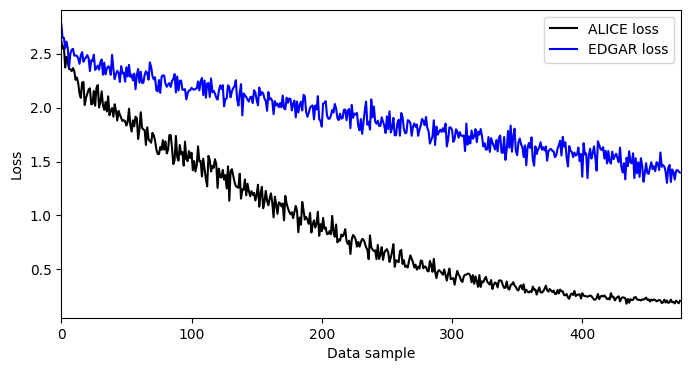

In [19]:
plt.figure(figsize = (8,4))
plt.plot(loss_alice, 'k', markersize = 8, label = 'ALICE loss')
plt.plot(loss_edgar, 'b', markersize = 8, label = 'EDGAR loss')

plt.legend()
plt.gca().set(xlabel='Data sample', ylabel='Loss', xlim = [0, num_samples])
plt.show()

# Qualitative Assessment

In [20]:
# input
x = tokenizer.encode('What did the Red Queen say to Alice?', return_tensors='pt').to(device)

# get the output
out_alice = model_alice.generate(x, max_new_tokens = 120, do_sample = True, pad_token_id = 50256)
out_edgar = model_edgar.generate(x, max_new_tokens = 120, do_sample = True, pad_token_id = 50256)

# print both models' outputs
print('** Alice model says:')
print(tokenizer.decode(out_alice[0].cpu()))

print('\n\n** Edgar model says:')
print(tokenizer.decode(out_edgar[0].cpu()))

** Alice model says:
What did the Red Queen say to Alice?” thought Alice.

“Who said so,” said the Queen.

“That’s the important part,” said the King: “if the jury forget to
tell them!” so eagerly that they all needtries to get up the _very next
mushroom_, and, worst of all, to see the look in the alligator’s eyes
that same moment: the all trying to get their ears cut off, they managed
to cut the Lizard 3


** Edgar model says:
What did the Red Queen say to Alice? I have no idea. Her
      voice is not, under any circumstances, heard. Besides, she has
      absolutely no consciousness of any of the things about her that
      might have happened to me; and I must, therefore, have no more
      hesitation in referring to the information which she has already
      supplied of the murder in the catacombs. The truth is, I had
      scarcely reached the brink of a
